In [ ]:
# -*- coding: utf-8 -*-
"""Program 18 AA 19001239x1388 proyecto FELIPE Crea imagenes y Marcas


En este programa creamos las imagenes para el entranamiento de las neuronas simil fashion

mayo 8 de 2025

En este progrmama, leeremos los archivos generados para en entrenamiento.
Y crearemos el corpus de entrenamiento, usando los archivos nuevos para fast MC.


          version 0.1 / mayo 8 de 2025.
"""

In [1]:
import time
from datetime import datetime, timedelta

import numpy as np
from numpy import asarray
from numpy import savetxt
from numpy import loadtxt

# Importing the basic libraries
import matplotlib.pyplot as plt
import pandas as pd
import os
import time

In [2]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [4]:
path = '/content/gdrive/MyDrive/Colab Notebooks/Fashion_Peaks'
os.chdir(path)

In [5]:
!ls

Creator_corpus_fashion_spectra.ipynb  imagenes_entrenamiento
fileBase_2000x1900.dat		      MonteCarlo_Modulo_3_Aplicacion.ipynb
fileCesio_2000x1900.dat		      program_crea_de_corpus_v0.ipynb


In [6]:
# Defining some parameters
nroChannel = 8192
nroBinSpe = 8192

nroCut = 76 # número de canales que se completaran con ceros al comienzo y al final, simétrico
nroBin = 1900

aa = 0.355574
bb = -4.26897 ## E=A.m+B en keVs
channel = np.linspace(0, nroBin, num=nroBin)
channelSpe = np.linspace(0, nroBinSpe, num=nroBinSpe)
# convertimos los factores de escala según el nuevo formato de 2048
# el pico de Cs está en :   1870	661.483	0.26968068306434
#aa_2048 = aa*4
#bb_2048 = (bb+0.8)*4
#bb_2048 = (bb)*4
aSpe = aa
bSpe = bb+0.8
energySpe = channelSpe * aSpe + bSpe
energy = channel * aSpe + bSpe
E_Cs137 = 661.657 # 661.657
E_K40 = 1460.8

n_train = 10000
n_test  = 2000


In [7]:
"""----------------------------
### Leemos el archivo con los 2000 espectros para la base
"""

fileBase = 'fileBase_2000x1900.dat'
fileCesio = 'fileCesio_2000x1900.dat'

# Leer el archivo de texto
cantSpectra = 2000
numBaseBins = 1900
leeBaseSpectra = np.loadtxt(fileBase)
# Asegurarse de que el tamaño del array sea correcto para el reshape
if leeBaseSpectra.size != cantSpectra * numBaseBins:
    raise ValueError("El tamaño del array no coincide con las dimensiones especificadas")

# Hacer el reshape del array
BaseSpectraReshaped = leeBaseSpectra.reshape((cantSpectra, numBaseBins))
baseSpectra = BaseSpectraReshaped.copy()


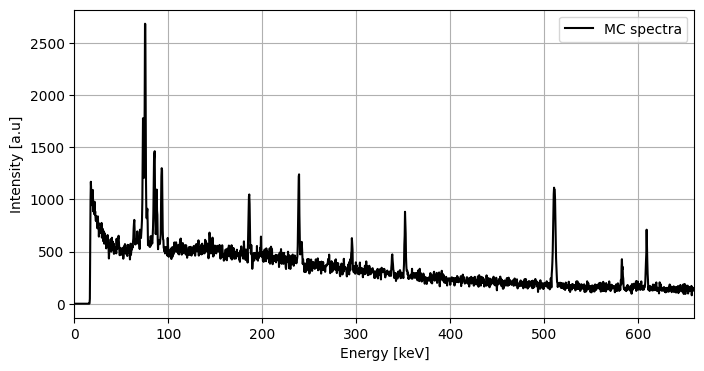

In [8]:
plt.figure(figsize=(8,4))
plt.plot(energy, baseSpectra[9] , 'k',label='MC spectra')
# factorCicterra_68   = Cicterra_68[2].max() * 1.001 # Aqui dividimos por el maximo para aumentar la escala y lo agrandamos en un 0.1%
#plt.plot(spectrumEnergy, baseSpectra[3],'b' ,label = "2")
plt.xlim(0,660)
plt.legend(); plt.grid(); plt.xlabel("Energy [keV]"); plt.ylabel("Intensity [a.u]")
plt.show()


Array cargado y reestructurado:


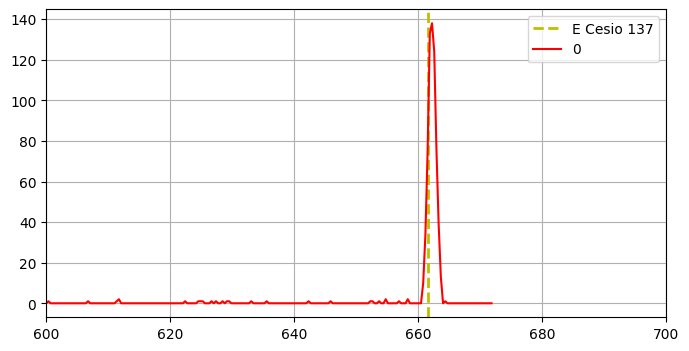

In [9]:
"""-----------------------------
#### Hacemos lo mismo con el espectro de Cesio 137
----------------------------
##### Leemos el archivo para el Monte Carlo
"""

# Leer el archivo de texto

numCesioBins = 1900

#fileCesio = 'fileCesio_2000x482.txt'
leeCesioSpectra = np.loadtxt(fileCesio)

# Asegurarse de que el tamaño del array sea correcto para el reshape
if leeCesioSpectra.size != cantSpectra * numCesioBins:
    raise ValueError("El tamaño del array no coincide con las dimensiones especificadas")

# Hacer el reshape del array
CesioSpectraReshaped = leeCesioSpectra.reshape((cantSpectra, numCesioBins))
cesioSpectra = CesioSpectraReshaped.copy()
print("Array cargado y reestructurado:")
# print(BaseSpectraReshaped)

plt.figure(figsize=(8,4))
plt.axvline(x=E_Cs137, color='y', linestyle='--', linewidth=2, label='E Cesio 137')
#plt.plot(plt.plot(energySpe[3:1900],cesioSpectra[0][:1897], baseSpectra[13], 'k',label='Measured $\gamma$ spectra 68')
#plt.plot(energySpe[:1900]+7.5, spectrumIntensity, 'k',label='Measured $\gamma$ spectra 68')
plt.plot(energySpe[3:1900],cesioSpectra[0][:1897], 'r', label = "0")
#plt.plot(energy,cesioSpectra[3], label = "1")
#plt.plot(energy,cesioSpectra[2], label = "2")
#plt.plot(energy,cesioSpectra[3], label = "3")

#plt.ylim(-10, 50)
plt.xlim(600, 700)
plt.legend()
plt.grid()

In [12]:
%%time
# Creating the training data
# este cálculo es muy muy lento, con 15000 es lento, lo bajo a 10000
# CPU times: user 2min 42s, sys: 2min 55s, total: 5min 37s
# Wall time: 5min 40s

n_train = 2000 # 15000

cantSpectra = 2000
numBaseBins = 1900

# x_train, y_train =  Spectra()
x_train = np.array([])
y_train = np.array([])

"""
baseSpectra_normalized_shift = np.roll(baseSpectra_normalized, -8)

baseSpectra_normalized_shift[-8:] = baseSpectra_normalized[-8:]
"""
for jj in range(0,n_train):


   idx = int(np.random.uniform(low=0, high=cantSpectra))
   idy = int(np.random.uniform(low=0, high=cantSpectra))

   base  = baseSpectra[idx]

   cesio = cesioSpectra[idy] * 0.3 # Divido por 3.33 puews son muy grandes

   Spectrum = base + cesio

   factor   = Spectrum.max() * 1.001 # Aqui dividimos por el maximo para aumentar la escala y lo agrandamos en un 0.1%
   Spectrum = Spectrum / factor
   Cesium   = cesio / factor

   x_train = np.concatenate((x_train, Spectrum))
   y_train = np.concatenate((y_train, Cesium))

x_train = np.reshape(x_train, (n_train, numBaseBins))
y_train = np.reshape(y_train, (n_train, numBaseBins))
#print(y_train[1499,:])

CPU times: user 10.5 s, sys: 188 ms, total: 10.6 s
Wall time: 10.6 s


1707


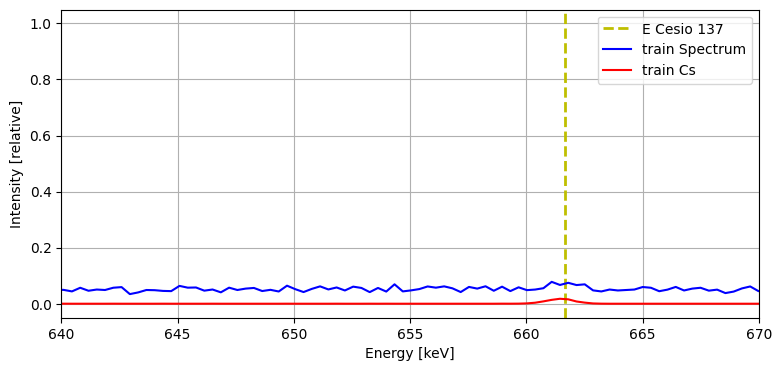

In [13]:
"""-----------------------------------------
## Ahora debemos generar el corpus
Para ello generaremos n_train = 10000 espectros de ambos casos.
Luego de sumarán, se normalizarán a 1 y con ello se obtendrán los X, y con correspondiente espectro de Cesio, dividido por el mismo factor de normalización que la suma, se construirá el conjunto de los y.
Similarmente se harán para una generación N' para el corpus de los test.

-------------------------
## Corpus Train
"""

plt.figure(figsize=(9,4))
idx = np.random.randint(0, n_train - 1)
print(idx)
plt.axvline(x=E_Cs137, color='y', linestyle='--', linewidth=2, label='E Cesio 137')
plt.plot(energy,x_train[idx], 'b', label = 'train Spectrum')
plt.plot(energy,y_train[idx], 'r', label = 'train Cs')
plt.grid()
plt.xlabel('Energy [keV]')
plt.ylabel('Intensity [relative]')
plt.legend()
plt.xlim(640, 670)
plt.show()
# print(x_train[idx].max())

15.244499971135939


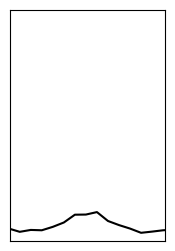

In [14]:
#spectrumEnergy


#print(idx)

# idx = 1883
plt.figure(figsize=(2,3))
idx = np.random.randint(0, n_test - 1)
area = y_train[idx].sum() * 10
print(area)
plt.plot(energy,x_train[idx], 'k')
plt.xlim(659, 664)
plt.ylim(0, 1.2)
plt.xticks([])  # Quitar los ticks del eje x
plt.yticks([])  # Quitar los ticks del eje y

plt.show()
#plt.save()

75.03477488836202
Tamaño de imagen: 30 x 60 píxeles


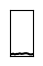

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Tamaño deseado en pixeles
width_px = 30
height_px = 2 * width_px
dpi = 100

# Convertir a pulgadas
figsize = (width_px / dpi, height_px / dpi)

# Crear figura con relación 1:2
fig = plt.figure(figsize=figsize, dpi=dpi)
idx = np.random.randint(0, n_test - 1)
area = y_train[idx].sum() * 1000
print(area)
plt.plot(energy, x_train[idx], 'k')
plt.xlim(659, 664)
plt.ylim(0, 1.2)

# Obtener tamaño en píxeles
width_px  = int(fig.get_size_inches()[0] * fig.dpi)
height_px = int(fig.get_size_inches()[1] * fig.dpi)

print(f"Tamaño de imagen: {width_px} x {height_px} píxeles")
plt.xticks([])  # Quitar los ticks del eje x
plt.yticks([])  # Quitar los ticks del eje y

# Guardar figura
plt.savefig("mi_figura30x60.png", dpi=fig.dpi, bbox_inches='tight')
plt.show()


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Tamaño deseado en pixeles
width_px = 40
height_px = 2 * width_px
dpi = 100

# Convertir a pulgadas
figsize = (width_px / dpi, height_px / dpi)

# Crear figura con relación 1:2
fig = plt.figure(figsize=figsize, dpi=dpi)

# Tu contenido (ejemplo)
plt.plot(np.linspace(0, 1, 100), np.random.rand(100), 'k')
plt.xticks([]); plt.yticks([]); plt.axis('off')

# Guardar la imagen exactamente en 20x40 píxeles
plt.savefig("figura_20x40.png", dpi=dpi, bbox_inches='tight', pad_inches=0)
plt.close()


In [18]:
def punto_medio_intervalo(n: int) -> int:
    """
    Dado un número entero n entre 0 y 20000 (inclusive),
    retorna el punto medio del intervalo de 500 unidades al que pertenece n.
    """
    if n == 0:
        # Caso especial: 0 se considera en el intervalo [0, 500]
        return 250
    # Calcular el índice del intervalo (k) usando división entera ajustada
    k = (n - 1) // 500
    # Devolver el punto medio correspondiente al intervalo k
    return k * 500 + 250

#for ii in range (0, 20000, 100):
    #print(ii, punto_medio_intervalo(ii))


In [19]:
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd

# Directorio de salida
output_dir = "imagenes_entrenamiento"
os.makedirs(output_dir, exist_ok=True)

# Tamaño de imagen (pixeles)
width_px = 30
height_px = 2 * width_px
dpi = 100
figsize = (width_px / dpi, height_px / dpi)

# Lista para almacenar pares (filename, label)
registros = []

# Recorrer todos los espectros
n_test = 20
for idx in range(n_test):
    # Área como label
    area = int(y_train[idx].sum() * 1000)
    area = punto_medio_intervalo(area)
    label = int(round(area))  # Redondear a entero

    # Crear figura
    fig = plt.figure(figsize=figsize, dpi=dpi)
    plt.plot(energy, x_train[idx], 'k')
    plt.xlim(659, 664)
    plt.ylim(0, 1.2)
    plt.xticks([])
    plt.yticks([])
    plt.axis('off')

    # Nombre del archivo
    filename = f"spectro_{idx:05d}.png"
    filepath = os.path.join(output_dir, filename)

    # Guardar imagen sin bordes
    plt.savefig(filepath, dpi=dpi, bbox_inches='tight', pad_inches=0)
    plt.close(fig)

    # Guardar label
    registros.append((filename, label))

# Guardar labels en CSV
df = pd.DataFrame(registros, columns=["filename", "label"])
df.to_csv(os.path.join(output_dir, "labels.csv"), index=False)

print(f"Se generaron {n_test} imágenes en '{output_dir}' con sus labels.")


Se generaron 20 imágenes en 'imagenes_entrenamiento' con sus labels.


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import pandas as pd
import os

class SpectraDataset(Dataset):
    def __init__(self, csv_file, root_dir, transform=None):
        self.labels_df = pd.read_csv(csv_file)
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(self.labels_df)

    def __getitem__(self, idx):
        img_name = os.path.join(self.root_dir, self.labels_df.iloc[idx, 0])
        image = Image.open(img_name).convert('L')  # escala de grises

        label = self.labels_df.iloc[idx, 1]
        label = torch.tensor(label, dtype=torch.float32)  # usar long si es clasificación

        if self.transform:
            image = self.transform(image)

        return image, label


ModuleNotFoundError: No module named 'torchvision'

In [ ]:
# Transformación (opcional: normalizar a [0,1])
transform = transforms.Compose([
    transforms.ToTensor(),  # convierte a [C,H,W] con valores entre 0 y 1
])

# Crear dataset y dataloader
dataset = SpectraDataset(csv_file="imagenes_entrenamiento/labels.csv",
                         root_dir="imagenes_entrenamiento",
                         transform=transform)

dataloader = DataLoader(dataset, batch_size=32, shuffle=True)

# Prueba de un batch
for images, labels in dataloader:
    print(images.shape)  # [32, 1, 60, 30] si las imágenes son 30x60
    print(labels)
    break


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import pandas as pd
import os

class SpectraClassificationDataset(Dataset):
    def __init__(self, csv_file, root_dir, transform=None, bins=None):
        self.labels_df = pd.read_csv(csv_file)
        self.root_dir = root_dir
        self.transform = transform
        self.bins = bins  # opcional: usar para categorizar

    def __len__(self):
        return len(self.labels_df)

    def __getitem__(self, idx):
        img_name = os.path.join(self.root_dir, self.labels_df.iloc[idx, 0])
        image = Image.open(img_name).convert('L')  # escala de grises
        area = self.labels_df.iloc[idx, 1]

        if self.bins is not None:
            label = np.digitize(area, self.bins) - 1  # clase entera
        else:
            label = int(round(area))  # clase = área redondeada

        label = torch.tensor(label, dtype=torch.long)

        if self.transform:
            image = self.transform(image)

        return image, label
